In [27]:
import random
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,precision_score, recall_score, f1_score, accuracy_score
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from imblearn.over_sampling import SMOTE


In [7]:

# Load the dataset
data = pd.read_csv("../data/processed/trained_cleaned.csv")

# Display the first few rows
data.head()

# Explore the structure of the data
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30890 entries, 0 to 30889
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Annual_Income                 30890 non-null  float64
 1   Num_Bank_Accounts             30890 non-null  int64  
 2   Num_Credit_Card               30890 non-null  int64  
 3   Interest_Rate                 30890 non-null  int64  
 4   Num_of_Loan                   30890 non-null  int64  
 5   Delay_from_due_date           30890 non-null  int64  
 6   Num_of_Delayed_Payment        30890 non-null  int64  
 7   Changed_Credit_Limit          30890 non-null  float64
 8   Num_Credit_Inquiries          30890 non-null  float64
 9   Outstanding_Debt              30890 non-null  float64
 10  Total_EMI_per_month           30890 non-null  float64
 11  Credit_History_Age_Months     30890 non-null  int64  
 12  Credit_Score_Encoded          30890 non-null  float64
 13  C

In [8]:


# Split features (X) and target (y)
X = data.drop(columns=["Credit_Score_Encoded"])
y = data["Credit_Score_Encoded"].astype("category")  # Similar to as.factor()

# Stratified split: 85% training, 15% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.15, 
    random_state=77, 
    stratify=y  # Equivalent to caret's createDataPartition with stratification
)


In [10]:
# Combine X_train and y_train is not needed in sklearn – just pass them separately
rf_model = RandomForestClassifier(n_estimators=1, random_state=77)

# Train the model
rf_model.fit(X_train, y_train)

# Save the model to a file
joblib.dump(rf_model, "../models/f_model.pkl")


['../models/f_model.pkl']

In [17]:


# Load model and predict
rf_model = joblib.load("../models/f_model.pkl")
predictions = rf_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", cm)

# Classification report (includes precision, recall, f1 per class)
print("\nClassification Report:\n", classification_report(y_test, predictions))

# Overall metrics
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average='weighted')  # or 'macro'
recall = recall_score(y_test, predictions, average='weighted')        # or 'macro'
f1 = f1_score(y_test, predictions, average='weighted')                # or 'macro'

# Print metrics
print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1 Score (weighted): {f1:.4f}")
  

Confusion Matrix:
 [[ 383  218   43]
 [ 217 2319  354]
 [  56  346  698]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.58      0.59      0.59       644
         1.0       0.80      0.80      0.80      2890
         2.0       0.64      0.63      0.64      1100

    accuracy                           0.73      4634
   macro avg       0.68      0.68      0.68      4634
weighted avg       0.73      0.73      0.73      4634


Accuracy: 0.7337
Precision (weighted): 0.7341
Recall (weighted): 0.7337
F1 Score (weighted): 0.7339


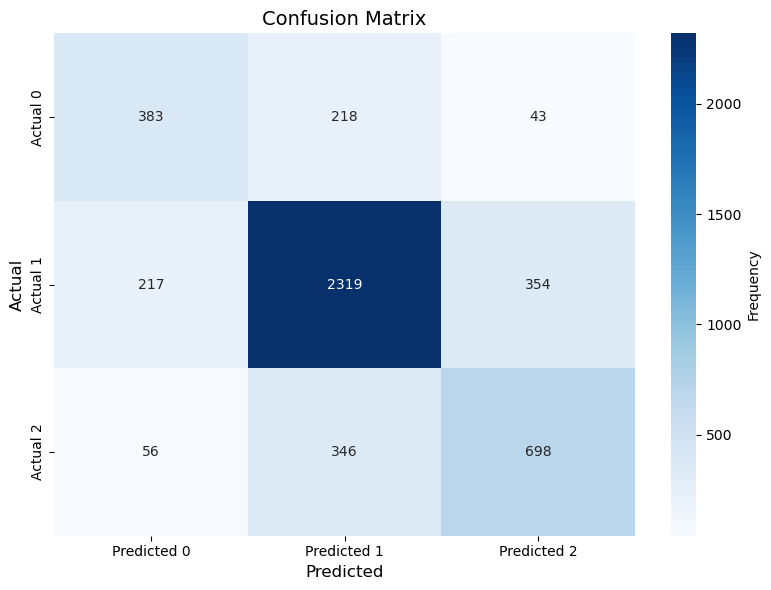

In [20]:
cm_df = pd.DataFrame(cm,
                     index=[f"Actual {i}" for i in range(len(cm))],
                     columns=[f"Predicted {i}" for i in range(len(cm[0]))])

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar_kws={'label': 'Frequency'})

plt.xlabel("Predicted", fontsize=12)
plt.ylabel("Actual", fontsize=12)
plt.title("Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()


In [23]:
# Suppress warnings and get minimum value
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    min_value = np.min(data)


In [24]:
# Equivalent of table(data$Credit_Score_Encoded) in Python
value_counts = data['Credit_Score_Encoded'].value_counts()
print(value_counts)


Credit_Score_Encoded
1.0    19262
2.0     7333
0.0     4295
Name: count, dtype: int64


In [26]:
# Convert column to categorical (factor equivalent)
data['Credit_Score_Encoded'] = data['Credit_Score_Encoded'].astype('category')

# Original class counts
class_counts = [4295, 19262, 7333]

# Calculate the target count as the average of the original class counts
target_count = sum(class_counts) // len(class_counts)

# Separate features and target
X = data.drop('Credit_Score_Encoded', axis=1)
y = data['Credit_Score_Encoded']

# Apply SMOTE (approx. equivalent to DMwR's SMOTE)
smote = SMOTE(sampling_strategy='auto', k_neighbors=5)
X_res, y_res = smote.fit_resample(X, y)

# Combine back into one DataFrame
over_smote = pd.concat([X_res, y_res], axis=1)

# Check the class distribution after sampling
print(over_smote['Credit_Score_Encoded'].value_counts())


Credit_Score_Encoded
0.0    19262
1.0    19262
2.0    19262
Name: count, dtype: int64


In [28]:
# Set seed (equivalent to set.seed(77))
random.seed(77)
np.random.seed(77)

# Display dataset dimensions
print("Original data shape:", data.shape)

# Display dataset structure
print("\nData info:")
print(data.info())

# Convert target column to categorical (factor equivalent)
data['Credit_Score_Encoded'] = data['Credit_Score_Encoded'].astype('category')

# Apply SMOTE (approximate equivalent to DMwR::SMOTE with perc.over = 800, perc.under = 200)
# Note: perc.over and perc.under aren't directly available in imblearn, so we use default 'auto' strategy.
X = data.drop('Credit_Score_Encoded', axis=1)
y = data['Credit_Score_Encoded']

smote = SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=77)
X_res, y_res = smote.fit_resample(X, y)

# Combine into a single DataFrame (similar to smote_data in R)
smote_data = pd.concat([X_res, y_res], axis=1)

# Display new dimensions
print("\nSMOTE data shape:", smote_data.shape)

# Display structure
print("\nSMOTE data info:")
print(smote_data.info())

# Show class distribution
print("\nClass distribution after SMOTE:")
print(smote_data['Credit_Score_Encoded'].value_counts())


Original data shape: (30890, 18)

Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30890 entries, 0 to 30889
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Annual_Income                 30890 non-null  float64 
 1   Num_Bank_Accounts             30890 non-null  int64   
 2   Num_Credit_Card               30890 non-null  int64   
 3   Interest_Rate                 30890 non-null  int64   
 4   Num_of_Loan                   30890 non-null  int64   
 5   Delay_from_due_date           30890 non-null  int64   
 6   Num_of_Delayed_Payment        30890 non-null  int64   
 7   Changed_Credit_Limit          30890 non-null  float64 
 8   Num_Credit_Inquiries          30890 non-null  float64 
 9   Outstanding_Debt              30890 non-null  float64 
 10  Total_EMI_per_month           30890 non-null  float64 
 11  Credit_History_Age_Months     30890 non-null  int64   
 12  C

In [29]:
# Equivalent of fwrite(smote_data, file = "smote.csv", sep = ",", quote = FALSE) in Python
smote_data.to_csv("smote.csv", sep=",", index=False, quoting=0)


In [30]:
# Features and target
X = smote_data.drop(columns=['Credit_Score_Encoded'])
y = smote_data['Credit_Score_Encoded'].astype('category')  # equivalent to as.factor

# Set random seed
random.seed(77)
np.random.seed(77)

# Train-test split (80-20), equivalent to createDataPartition in R
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [31]:
# Combine X_train and y_train into one DataFrame (optional, as scikit-learn uses separate X and y)
train_data = pd.concat([X_train, y_train.reset_index(drop=True)], axis=1)

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=500, random_state=42)
rf_model.fit(X_train, y_train)

# Save the model
joblib.dump(rf_model, "../models/v2_smote_model.pkl")


['../models/v2_smote_model.pkl']

In [33]:
# Load the saved model
loaded_model = joblib.load("../models/v2_smote_model.pkl")

# Make predictions on test data
predictions = loaded_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", cm)

# Optional: classification report for more metrics
print("\nClassification Report:\n", classification_report(y_test, predictions))


Confusion Matrix:
 [[3563  208   81]
 [ 218 3220  415]
 [ 104  263 3486]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      0.92      0.92      3852
         1.0       0.87      0.84      0.85      3853
         2.0       0.88      0.90      0.89      3853

    accuracy                           0.89     11558
   macro avg       0.89      0.89      0.89     11558
weighted avg       0.89      0.89      0.89     11558



In [35]:
# Load the saved model
loaded_model = joblib.load("../models/v2_smote_model.pkl")

# Make predictions on the test set
predictions = loaded_model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", cm)

# Overall metrics (weighted for multi-class)
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average='weighted')
recall = recall_score(y_test, predictions, average='weighted')
f1 = f1_score(y_test, predictions, average='weighted')

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1 Score (weighted): {f1:.4f}")


Confusion Matrix:
 [[3563  208   81]
 [ 218 3220  415]
 [ 104  263 3486]]
Accuracy: 0.8885
Precision (weighted): 0.8883
Recall (weighted): 0.8885
F1 Score (weighted): 0.8882


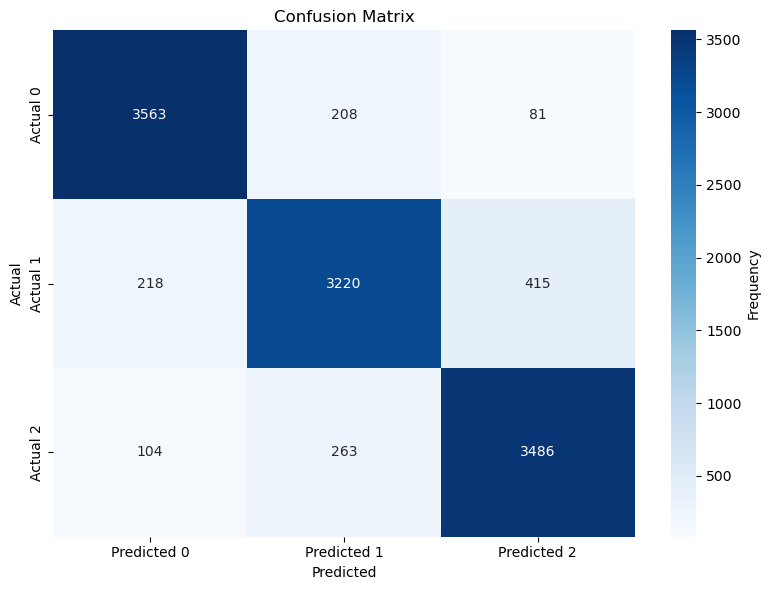

In [36]:
# Generate confusion matrix
cm = confusion_matrix(y_test, predictions)

# Convert to DataFrame for seaborn
cm_df = pd.DataFrame(cm,
                     index=[f"Actual {i}" for i in range(cm.shape[0])],
                     columns=[f"Predicted {i}" for i in range(cm.shape[1])])

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Frequency'})

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()
